# 01 - Data preparation and exploration

Run every cell in order. This notebook explains the source records and the finalized five-year dataset. The target labels are Slight, Serious and Fatal; Slight corresponds to minor in the problem statement. Records cover police-reported injury collisions in Great Britain.

The final table is already linked and feature-engineered. We demonstrate its inputs and split below; this notebook does **not** rerun the full geospatial matching pipeline. See `data/README.md` for source files and matching rules.

In [1]:
from pathlib import Path
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
DATA = Path('data')
assert (DATA / 'final_matched_2021_2025.csv.gz').exists(), 'Start Jupyter in the project folder.'
pd.set_option('display.max_columns', 100)

## 1. Inspect original collision and vehicle records

The shared `collision_index` links each collision with one or more vehicle records.

In [2]:
collisions = pd.read_csv(DATA / 'raw/dft-road-casualty-statistics-collision-2021.csv.gz', dtype={'collision_index': str}, low_memory=False)
vehicles = pd.read_csv(DATA / 'raw/dft-road-casualty-statistics-vehicle-2021.csv.gz', dtype={'collision_index': str}, low_memory=False)
print(f'2021 collisions: {len(collisions):,}; vehicle records: {len(vehicles):,}')
display(collisions[['collision_index','collision_severity','date','time','road_type','weather_conditions','speed_limit','road_surface_conditions']].head())

2021 collisions: 101,087; vehicle records: 186,443


,collision_index,collision_severity,date,time,road_type,weather_conditions,speed_limit,road_surface_conditions
0,2021170M10151,3,10/02/2021,14:44,6,1,30,3
1,2021170S11701,2,15/10/2021,21:20,3,1,30,1
2,2021111064046,3,05/07/2021,21:45,6,1,30,1
3,2021070535511,3,01/08/2021,17:02,6,1,60,1
4,2021070706357,3,11/10/2021,15:21,6,1,30,1


In [3]:
display(vehicles[['collision_index','vehicle_reference','vehicle_type']].head())
assert collisions.collision_index.is_unique
assert not vehicles.duplicated(['collision_index','vehicle_reference']).any()
vehicle_counts = vehicles.groupby('collision_index').size().rename('vehicle_records')
display(collisions[['collision_index','number_of_vehicles']].head().join(vehicle_counts, on='collision_index'))

,collision_index,vehicle_reference,vehicle_type
0,2021501144586,2,9
1,2021461116534,6,9
2,2021302101119,2,9
3,2021111022992,1,9
4,2021231075922,1,9


,collision_index,number_of_vehicles,vehicle_records
0,2021170M10151,1,1
1,2021170S11701,2,2
2,2021111064046,2,2
3,2021070535511,2,2
4,2021070706357,2,2


## 2. The seven input groups

Road type, weather, time, traffic density proxy, vehicle type, speed limit, and road surface conditions. Vehicle-type indicators and counts describe vehicles recorded for a collision. Time is represented cyclically. **AADF** is annual average daily vehicle flow: a traffic-volume proxy, not measured instantaneous density. Vehicle composition may not be known before a collision.

## 3. Load the finalized modelling table

The original pipeline linked eligible collisions to road geometry and previous-year AADF, using road number, a 50-metre maximum distance and an ambiguity check. This creates a selected major-road cohort, not a representative sample of every road.

In [4]:
data = pd.read_csv(DATA / 'final_matched_2021_2025.csv.gz', dtype={'collision_index': str}, float_precision='round_trip')
print('Prepared collisions:', f'{len(data):,}')
display(data.head())
display(pd.crosstab(data.year, data.severity))

Prepared collisions: 99,183


,collision_index,severity,year,count_point_id,road_type,weather_conditions,road_surface_conditions,speed_limit,time_sin,time_cos,vehicle_type_1,vehicle_type_10,vehicle_type_11,vehicle_type_16,vehicle_type_17,vehicle_type_18,vehicle_type_19,vehicle_type_2,vehicle_type_20,vehicle_type_21,vehicle_type_22,vehicle_type_23,vehicle_type_3,vehicle_type_33,vehicle_type_4,vehicle_type_5,vehicle_type_8,vehicle_type_9,vehicle_type_90,vehicle_type_97,vehicle_type_98,vehicle_type_99,vehicle_type_missing,aadf_motor_vehicles_per_day,time_sin_2,time_cos_2,time_sin_3,time_cos_3,vehicle_composition_cycle,vehicle_composition_motorcycle,vehicle_composition_car_taxi,vehicle_composition_bus,vehicle_composition_goods,vehicle_composition_other
0,2021010287149,Serious,2021,29037,3,1.0,1.0,30,0.793353,0.608761,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,44115,0.965926,-0.258819,0.382683,-0.923880,0.0,0.0,2.0,0.0,0.0,0.0
1,2021010287155,Fatal,2021,17576,2,1.0,1.0,30,0.917060,0.398749,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,25589,0.731354,-0.681998,-0.333807,-0.942641,0.0,0.0,1.0,0.0,0.0,0.0
2,2021010287167,Slight,2021,28532,6,9.0,1.0,20,0.598325,-0.801254,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,15663,-0.958820,0.284015,0.938191,0.346117,0.0,0.0,2.0,0.0,0.0,0.0
3,2021010287168,Slight,2021,36678,6,8.0,2.0,30,0.608761,-0.793353,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,16312,-0.965926,0.258819,0.923880,0.382683,0.0,0.0,1.0,1.0,0.0,0.0
4,2021010287234,Slight,2021,56759,3,4.0,2.0,40,-0.793353,0.608761,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,26537,-0.965926,-0.258819,-0.382683,-0.923880,0.0,0.0,4.0,0.0,0.0,0.0


severity,Fatal,Serious,Slight
year,,,
2021,216,3596,16271
2022,240,4034,16232
2023,234,4106,16016
2024,272,4071,14833
2025,204,4219,14639


### Follow one collision from the raw data to the prepared table

This is a real 2021 example. We inspect the original inputs and demonstrate how time and vehicle information are represented. The precomputed road-link match supplies the count-point ID; this cell does not reproduce the geospatial matching.

In [5]:
import numpy as np
example = data[data.year == 2021].iloc[0]
crash_id = example.collision_index
raw_crash = collisions.loc[collisions.collision_index == crash_id].iloc[0]
raw_vehicles = vehicles.loc[vehicles.collision_index == crash_id, ['vehicle_reference','vehicle_type']]
print('Collision ID:', crash_id, '| road count point:', example.count_point_id)
display(raw_crash[['time','road_type','weather_conditions','speed_limit','road_surface_conditions']].to_frame('raw value'))
display(raw_vehicles)
display(example[['time_sin','time_cos','vehicle_composition_cycle','vehicle_composition_motorcycle','vehicle_composition_car_taxi','vehicle_composition_bus','vehicle_composition_goods','vehicle_composition_other']].to_frame('prepared value'))

Collision ID: 2021010287149 | road count point: 29037


,raw value
time,03:30
road_type,3
weather_conditions,1
speed_limit,30
road_surface_conditions,1


,vehicle_reference,vehicle_type
78042,1,9
138823,2,9


,prepared value
time_sin,0.793353
time_cos,0.608761
vehicle_composition_cycle,0.0
vehicle_composition_motorcycle,0.0
vehicle_composition_car_taxi,2.0
vehicle_composition_bus,0.0
vehicle_composition_goods,0.0
vehicle_composition_other,0.0


In [6]:
clock = pd.to_datetime(raw_crash['time'], format='%H:%M')
minutes = clock.hour * 60 + clock.minute
time_sin = np.sin(2 * np.pi * minutes / 1440)
time_cos = np.cos(2 * np.pi * minutes / 1440)
print('Time:', raw_crash['time'], '| calculated sin/cos:', round(time_sin, 4), round(time_cos, 4))
print('Stored sin/cos:    ', round(example.time_sin, 4), round(example.time_cos, 4))
assert np.isclose(time_sin, example.time_sin) and np.isclose(time_cos, example.time_cos)
print('A cyclical encoding places times just before and just after midnight close together.')

Time: 03:30 | calculated sin/cos: 0.7934 0.6088
Stored sin/cos:     0.7934 0.6088
A cyclical encoding places times just before and just after midnight close together.


### Check the previous year's AADF value

We look up the count-point ID already matched to the collision. The example 2021 crash uses 2020 average daily flow; this is not an instantaneous measurement at the crash time.

In [7]:
traffic = pd.read_csv(DATA / 'raw/dft_traffic_counts_aadf.zip', usecols=['count_point_id','year','all_motor_vehicles'], low_memory=False)
traffic_row = traffic[(traffic.year == 2020) & (traffic.count_point_id == example.count_point_id)]
assert len(traffic_row) == 1
display(traffic_row)
print('Prepared AADF:', example.aadf_motor_vehicles_per_day)
assert float(traffic_row.iloc[0].all_motor_vehicles) == example.aadf_motor_vehicles_per_day

,count_point_id,year,all_motor_vehicles
150024,29037,2020,44115


Prepared AADF: 44115


In [8]:
assert data.collision_index.is_unique
assert set(data.severity) == {'Slight', 'Serious', 'Fatal'}
assert set(data.year) == {2021, 2022, 2023, 2024, 2025}
print('Duplicate collision IDs:', data.collision_index.duplicated().sum())
display(data.isna().sum().sort_values(ascending=False).head(12).rename('missing_values'))

Duplicate collision IDs: 0


road_surface_conditions    77
weather_conditions          3
collision_index             0
severity                    0
count_point_id              0
year                        0
road_type                   0
speed_limit                 0
time_sin                    0
time_cos                    0
vehicle_type_1              0
vehicle_type_10             0
Name: missing_values, dtype: int64

Unknown values are retained as unknown. Each model notebook fits its imputation and encoding pipeline on training rows only.

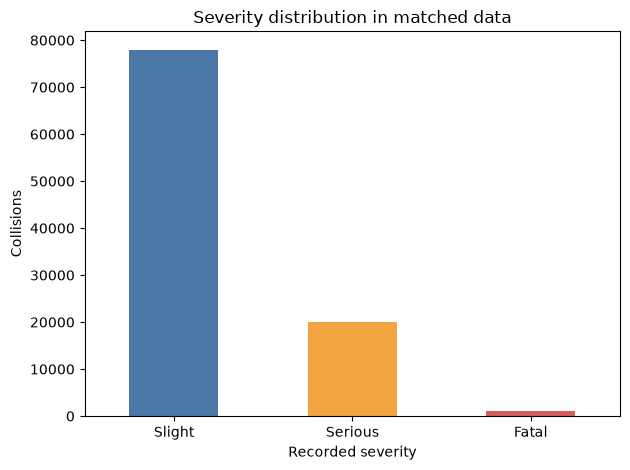

,collisions,percentage
severity,,
Slight,77991,78.63
Serious,20026,20.19
Fatal,1166,1.18


In [9]:
order = ['Slight', 'Serious', 'Fatal']
counts = data.severity.value_counts().reindex(order)
ax = counts.plot.bar(color=['#4c78a8','#f2a541','#d65b5b'], title='Severity distribution in matched data')
ax.set(xlabel='Recorded severity', ylabel='Collisions')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(counts.rename('collisions').to_frame().assign(percentage=(counts / counts.sum() * 100).round(2)))

## 4. Chronological split

2021-2023: initial training; 2024: validation for decision multipliers; 2025: evaluation after refitting on 2021-2024. The 2025 data were previously inspected, so they are **not an untouched final test**. Road links may recur across years.

In [10]:
train = data[data.year.isin([2021,2022,2023])]
validation = data[data.year == 2024]
test = data[data.year == 2025]
assert (len(train),len(validation),len(test)) == (60945,19176,19062)
display(pd.DataFrame({'period':['2021-2023','2024','2025'],'purpose':['Initial training','Validation','Evaluation'],'collisions':[len(train),len(validation),len(test)]}))
display(pd.crosstab(test.year,test.severity))

,period,purpose,collisions
0,2021-2023,Initial training,60945
1,2024,Validation,19176
2,2025,Evaluation,19062


severity,Fatal,Serious,Slight
year,,,
2025,204,4219,14639


## 5. Discussion

Explain class imbalance, how the seven feature groups map to columns, why AADF is a proxy, and why the earlier inspection of 2025 limits the evaluation. Then open the model notebooks.